<a href="https://colab.research.google.com/github/Abonty18/ELEC-872-WORKSHOPS/blob/main/Week10_Adversarial_Debiasing_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ELEC 872 Week 10: Adversarial Debiasing

This notebook covers Q1-Q12 of the Nov. 24 workshop using the provided code as
the starting point. Work through the plots and discuss interpretations with
your teammate before writing your own answers.

**CPU is enough. No GPU and no separate code ZIP upload are needed.**
The updated source is embedded in the first cell. All runs use seed 42 and 20
epochs by default. There are 12 distinct model fits; the histogram and threshold
questions reuse existing models. Completed matching runs are preserved on Drive.

Paper: Zhang, Lemoine and Mitchell (2018),
[Mitigating Unwanted Biases with Adversarial Learning](https://arxiv.org/abs/1801.07593).
Data: [UCI Adult](https://archive.ics.uci.edu/dataset/2/adult).
The supplied 64-64 MLP is retained, so this is not an exact paper reproduction.


## 1. Setup and save location
Leave `SAVE_TO_DRIVE=True` to keep the code and results after a disconnect.
Allow the Drive connection when prompted. This cell does not ask you to upload a ZIP.


In [1]:
from pathlib import Path
import base64, hashlib, importlib.util, io, os, subprocess, sys, zipfile

SAVE_TO_DRIVE = True
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB and SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/Week10_Debiasing")
elif IN_COLAB:
    ROOT = Path("/content/Week10_Debiasing")
else:
    ROOT = Path.cwd()/"Week10_Debiasing"
ROOT.mkdir(parents=True, exist_ok=True)

SOURCE_ZIP = base64.b64decode('...')
assert hashlib.sha256(SOURCE_ZIP).hexdigest() == '361a137ea925004051fa4c61839251920c37c50b9bde8e4ac9c9196839085f3b'
with zipfile.ZipFile(io.BytesIO(SOURCE_ZIP)) as archive:
    for name in archive.namelist():
        relative = Path(name)
        assert not relative.is_absolute() and ".." not in relative.parts
        target = ROOT/relative
        target.parent.mkdir(parents=True, exist_ok=True)
        content = archive.read(name)
        if target.exists() and target.read_bytes() != content:
            target.with_suffix(target.suffix+".previous").write_bytes(target.read_bytes())
        target.write_bytes(content)
PROJECT = ROOT/"Debiasing"
RESULTS = PROJECT/"results"
os.chdir(PROJECT)
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
subprocess.run([sys.executable,"-m","pip","install","-q","-r","requirements.txt"],check=True)
import torch
print("Project:",PROJECT)
print("PyTorch:",torch.__version__)
print("CPU works for every experiment. GPU available:",torch.cuda.is_available())


Mounted at /content/drive
Project: /content/drive/MyDrive/Week10_Debiasing/Debiasing
PyTorch: 2.14.1+cpu
CPU works for every experiment. GPU available: False


## 2. Experiment settings
Keep the same settings for all comparisons. If you change settings after a run
has completed, use a new results folder; this avoids mixing experiments.


In [2]:
EPOCHS = 20
SEED = 42
DEVICE = "cpu"  # change to "cuda" only if a GPU is actually available
BASE_ARGS = ["--epochs",str(EPOCHS),"--seed",str(SEED),"--device",DEVICE,
             "--threads","2","--output",str(RESULTS),"--cache-dir",str(PROJECT/"cache")]

def run(part="all", *extra):
    command = [sys.executable,"-u","workshop.py","--part",part,*BASE_ARGS,*map(str,extra)]
    subprocess.run(command,cwd=PROJECT,check=True)

from IPython.display import Image, display
import pandas as pd
import json

def show_fig(name):
    path=RESULTS/name
    if path.exists():
        display(Image(filename=str(path)))
    else:
        print("Run the corresponding experiment first:",name)

subprocess.run([sys.executable,"workshop.py","--list"],cwd=PROJECT,check=True)


CompletedProcess(args=['/usr/bin/python3', 'workshop.py', '--list'], returncode=0)

## 3. Train the three starting models
The data download is automatic and cached. The combined Adult records are split
56% training, 14% validation, and 30% test. All preprocessing is fitted on training
data only. Compared with the starter, a validation set is added for Q12.


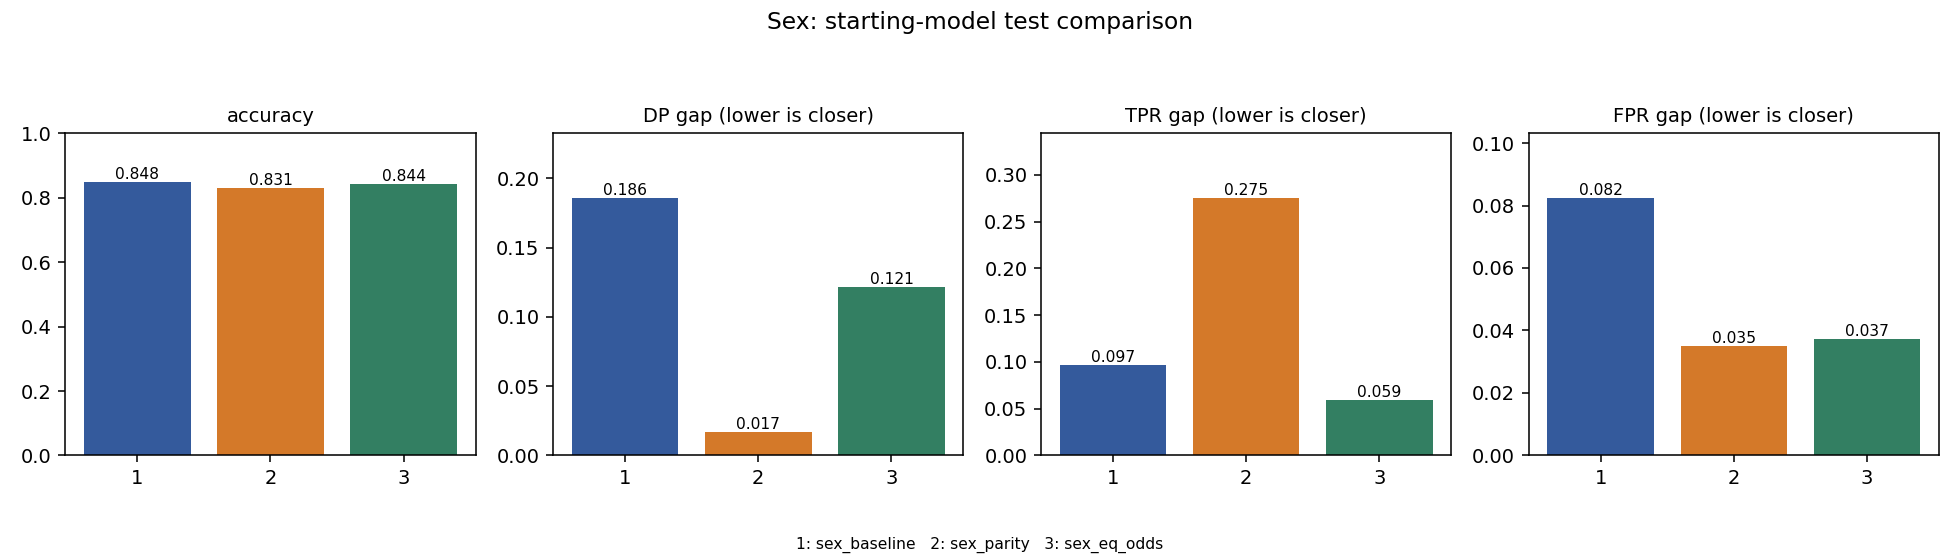

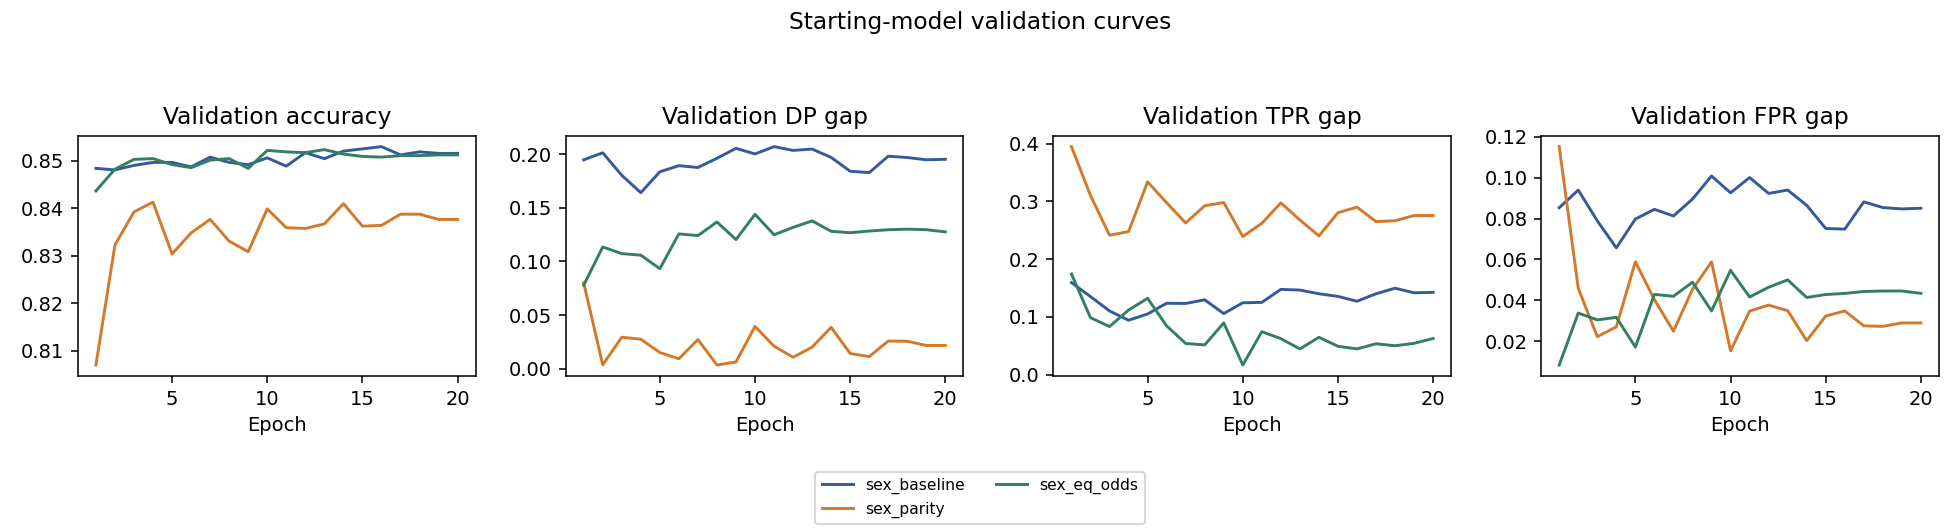

In [3]:
run("core")
show_fig("comparison.png")
show_fig("curves.png")


## Q1. Watch the adversary loss
Read both loss curves and the validation fairness gaps. The dashed line is the
empirical entropy reference: H(Z) for parity and H(Z|Y) for equalized odds. These
need not equal log(2), and they need not be the same for the two modes.
The baseline has no adversary, so its adversary loss is unavailable, not zero.


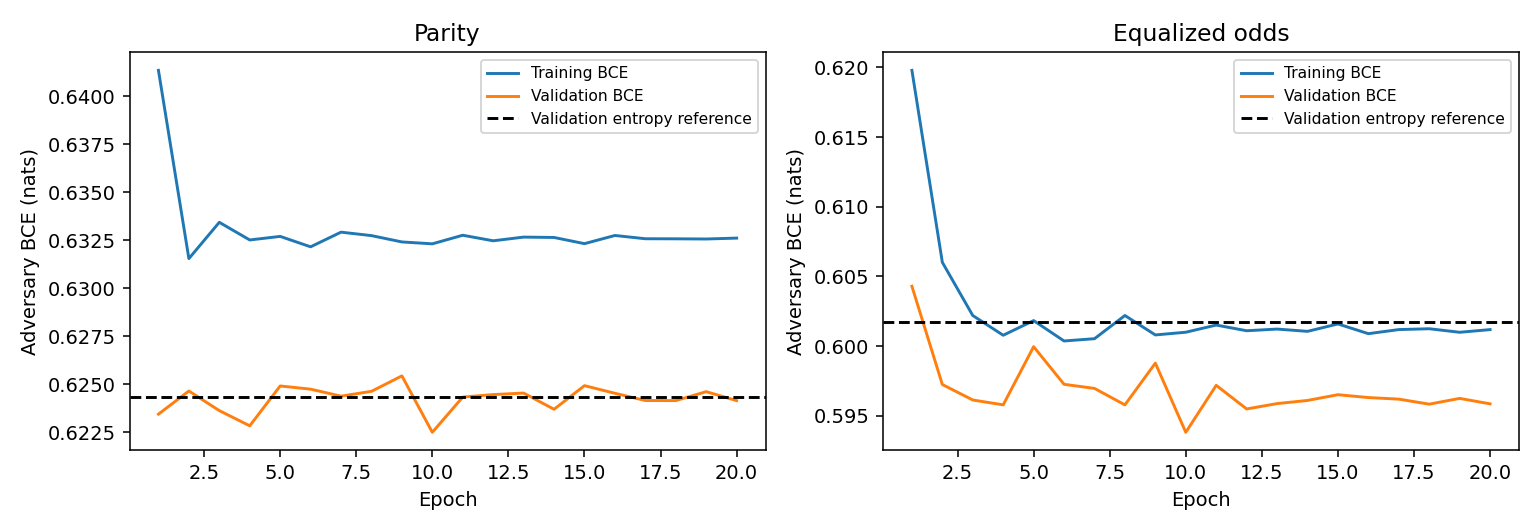

sex_parity


,epoch,loss_P,loss_A,val_loss_A,val_adversary_reference
0,1,0.490560,0.641342,0.623441,0.624354
1,2,0.356079,0.631541,0.624647,0.624354
2,3,0.374515,0.633430,0.623626,0.624354
3,4,0.364301,0.632511,0.622833,0.624354
4,5,0.363968,0.632697,0.624909,0.624354
5,6,0.353633,0.632154,0.624742,0.624354
6,7,0.360799,0.632918,0.624379,0.624354
7,8,0.358422,0.632738,0.624630,0.624354
8,9,0.351346,0.632408,0.625434,0.624354
9,10,0.351291,0.632310,0.622496,0.624354


sex_eq_odds


,epoch,loss_P,loss_A,val_loss_A,val_adversary_reference
0,1,0.421612,0.619782,0.604300,0.601742
1,2,0.335113,0.606015,0.597254,0.601742
2,3,0.328541,0.602201,0.596144,0.601742
3,4,0.325031,0.600786,0.595795,0.601742
4,5,0.323488,0.601838,0.599967,0.601742
5,6,0.318988,0.600376,0.597268,0.601742
6,7,0.317490,0.600539,0.596974,0.601742
7,8,0.316754,0.602203,0.595793,0.601742
8,9,0.314198,0.600809,0.598788,0.601742
9,10,0.311761,0.601003,0.593826,0.601742


In [4]:
show_fig("adversary_losses.png")
for name in ["sex_parity","sex_eq_odds"]:
    h=pd.read_csv(RESULTS/"runs"/name/"history.csv")
    print(name)
    display(h[["epoch","loss_P","loss_A","val_loss_A","val_adversary_reference"]])


## Q2. Compare score distributions
This reuses the baseline and parity models from cell 3. Each panel has two
overlapping density histograms using identical bins. The dashed line is the 0.5
decision threshold. Compare overlap and the amount of probability mass above 0.5.


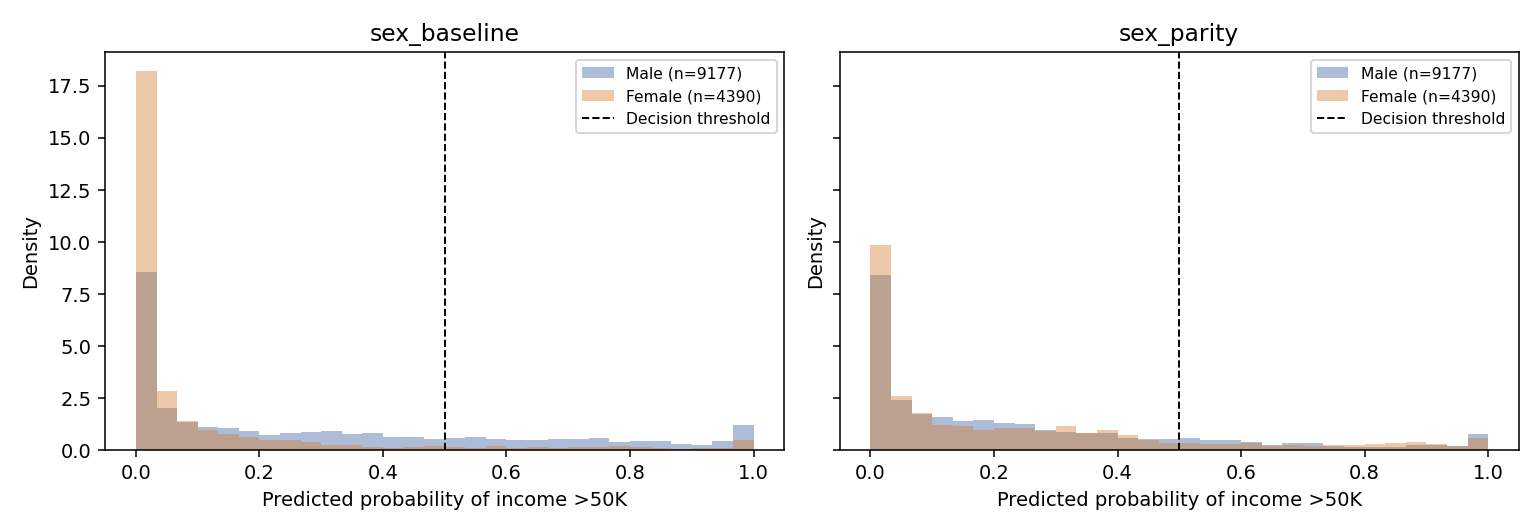

,run,accuracy,DP gap,TPR gap,FPR gap,selection_rate_g0,selection_rate_g1
0,sex_baseline,0.847719,0.185978,0.097101,0.082451,0.083827,0.269805
1,sex_parity,0.831061,0.016698,0.275344,0.034937,0.155581,0.172279


In [5]:
show_fig("scores.png")
display(pd.read_csv(RESULTS/"workshop_comparison.csv").query("run in ['sex_baseline','sex_parity']")
        [["run","accuracy","DP gap","TPR gap","FPR gap","selection_rate_g0","selection_rate_g1"]])


## Q3-Q4. Connect DP and conditional error rates
Use your baseline/parity results above and discuss why reducing one gap need not
reduce the other. A useful identity is:

P(Yhat=1 | Z=z) = TPR_z P(Y=1 | Z=z) + FPR_z [1-P(Y=1 | Z=z)].

Under equalized odds let both TPRs be t and both FPRs be f. The difference in
selection rates is (t-f) times the difference in base rates. What would exact DP
require if those base rates differ? No additional training is needed.


## Q5. Find proxies for sex
Sex is excluded from the predictor inputs. The table ranks the remaining numeric
and one-hot features by absolute Pearson correlation with sex on training data.
An association is not a causal explanation or a complete proxy test.


,feature,correlation,absolute_correlation
0,relationship_Husband,0.584960,0.584960
1,marital-status_Married-civ-spouse,0.442396,0.442396
2,relationship_Unmarried,-0.321780,0.321780
3,relationship_Wife,-0.314577,0.314577
4,occupation_Adm-clerical,-0.282085,0.282085
5,marital-status_Divorced,-0.249571,0.249571
6,hours-per-week,0.230802,0.230802
7,occupation_Craft-repair,0.226538,0.226538
8,marital-status_Widowed,-0.179290,0.179290
9,relationship_Not-in-family,-0.177127,0.177127


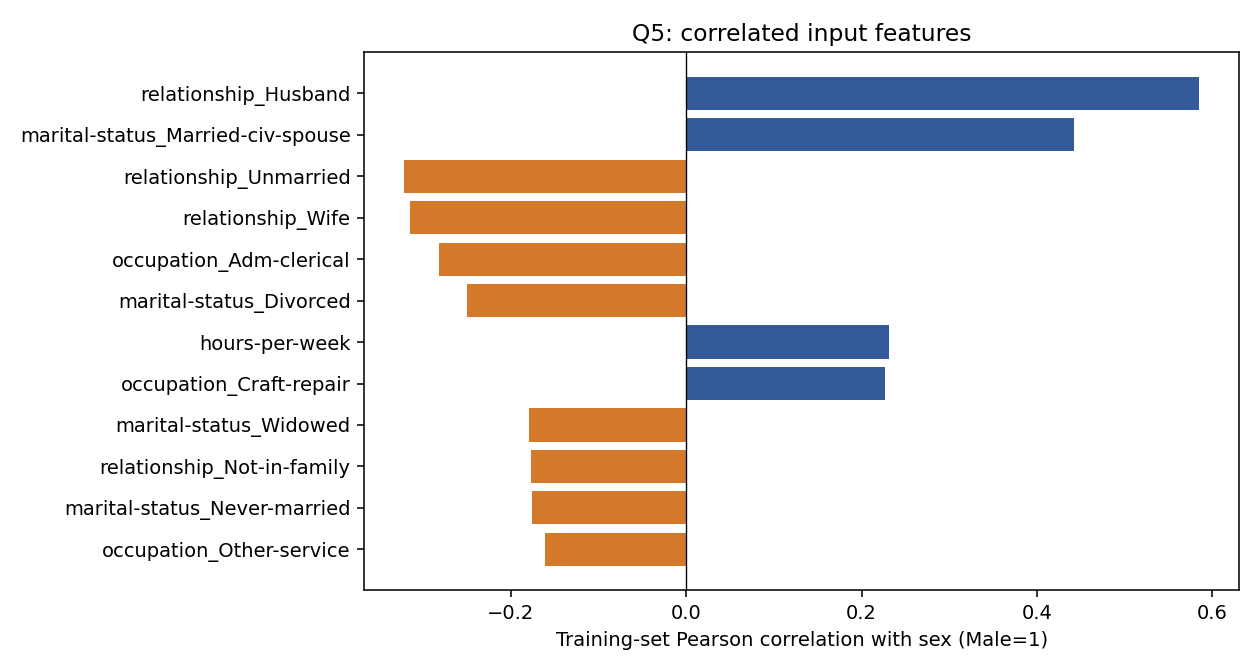

In [6]:
run("Q5")
display(pd.read_csv(RESULTS/"q5_feature_correlations.csv").head(15))
show_fig("q5_proxy_features.png")


## Q6. Give the adversary a hidden layer
Two additional fits add a 32-unit ReLU layer: parity and equalized odds. Compare
each with its matching original mode. Last-five-epoch variation summarizes one
trajectory; it does not establish robustness across random seeds.


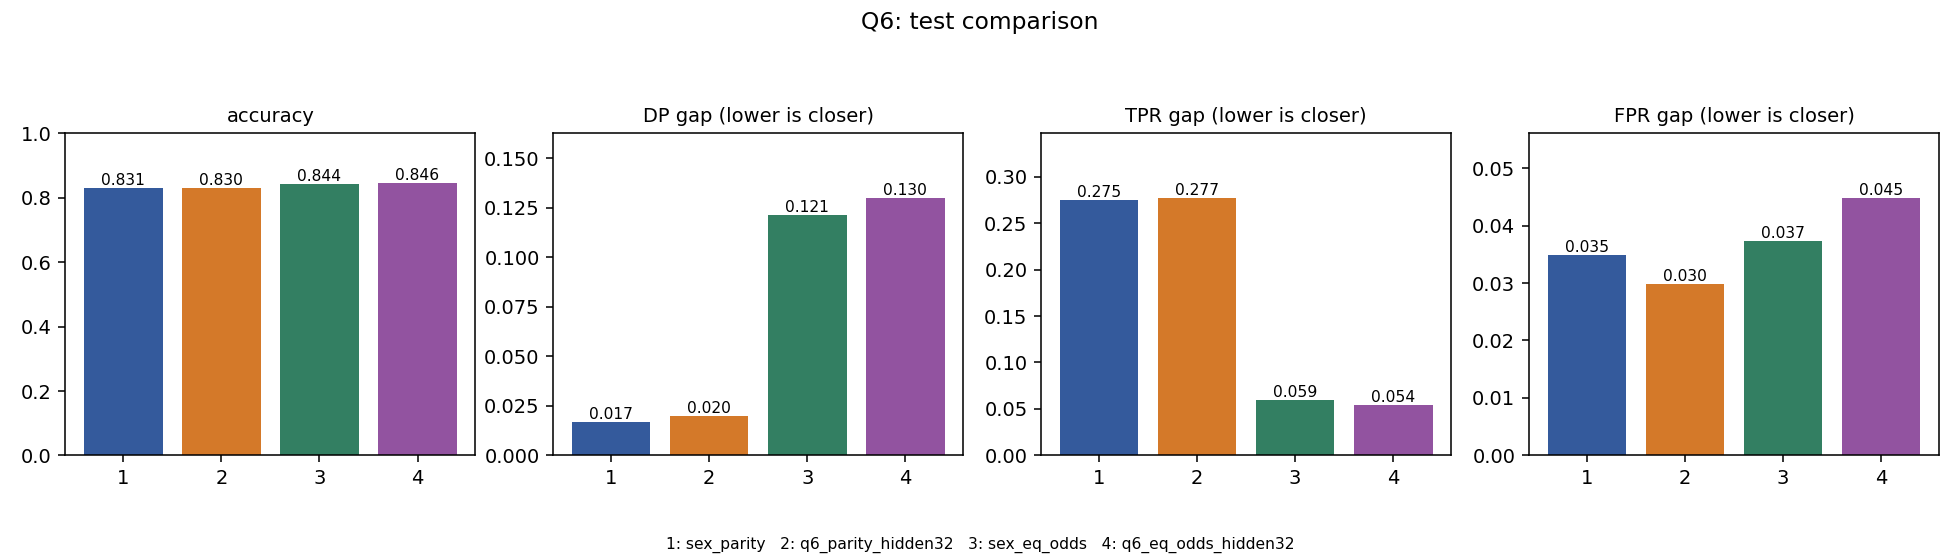

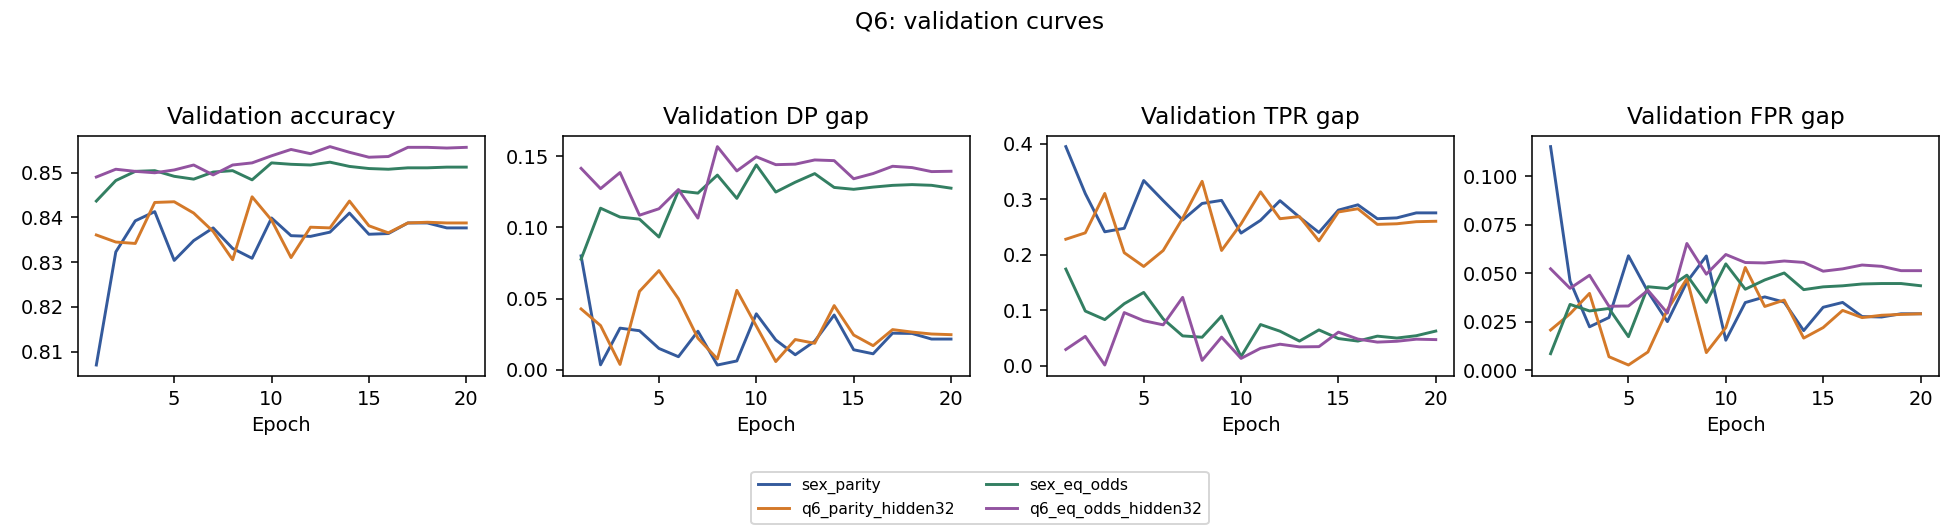

,run,tail_epochs,val_DP gap_mean,val_DP gap_std,val_TPR gap_mean,val_TPR gap_std,val_FPR gap_mean,val_FPR gap_std,loss_A_mean,loss_A_std,val_loss_A_mean,val_loss_A_std
1,sex_parity,5,0.021183,0.005260,0.274590,0.008920,0.029536,0.002740,0.632612,0.000068,0.624317,0.000208
2,sex_eq_odds,5,0.128944,0.000922,0.052981,0.005888,0.044068,0.000534,0.601108,0.000135,0.596099,0.000201
3,q6_parity_hidden32,5,0.024341,0.003871,0.262802,0.010330,0.028721,0.001206,0.632771,0.000098,0.624495,0.000199
4,q6_eq_odds_hidden32,5,0.140207,0.001892,0.046070,0.002201,0.052423,0.001177,0.601840,0.000194,0.596369,0.000160


In [7]:
run("Q6")
show_fig("q6_comparison.png")
show_fig("q6_curves.png")
stability=pd.read_csv(RESULTS/"stability_last5.csv")
display(stability[stability.run.isin(["sex_parity","q6_parity_hidden32","sex_eq_odds","q6_eq_odds_hidden32"])])


## Q7. Grow alpha over optimization steps
This is one additional equalized-odds fit. It uses alpha_t=sqrt(t) and the paired
predictor learning rate lr_0/t, where t counts minibatches starting at 1. The paper
used the decreasing step size to control the growing weight. This changes two
schedules; it does not isolate the effect of alpha alone. Inspect group TPRs and
selection rates as well as small fairness gaps.


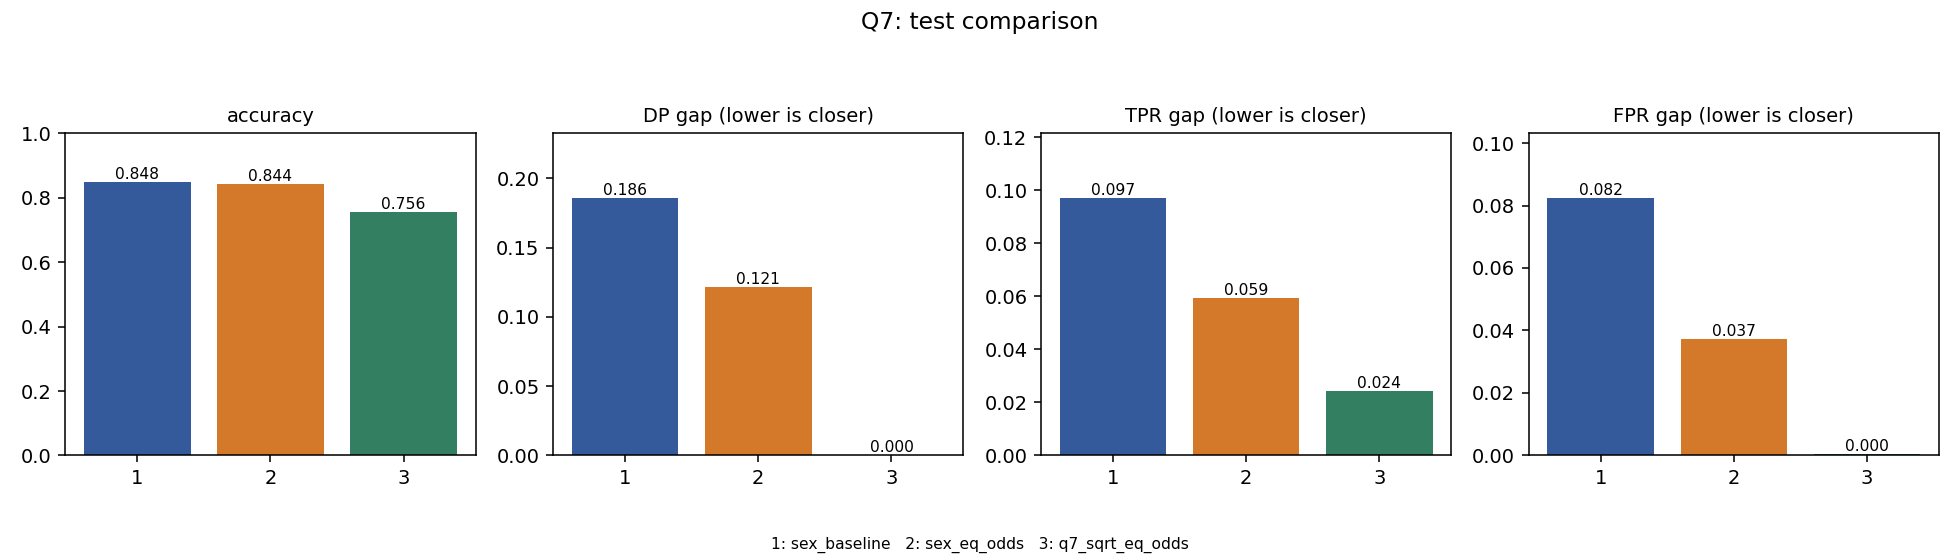

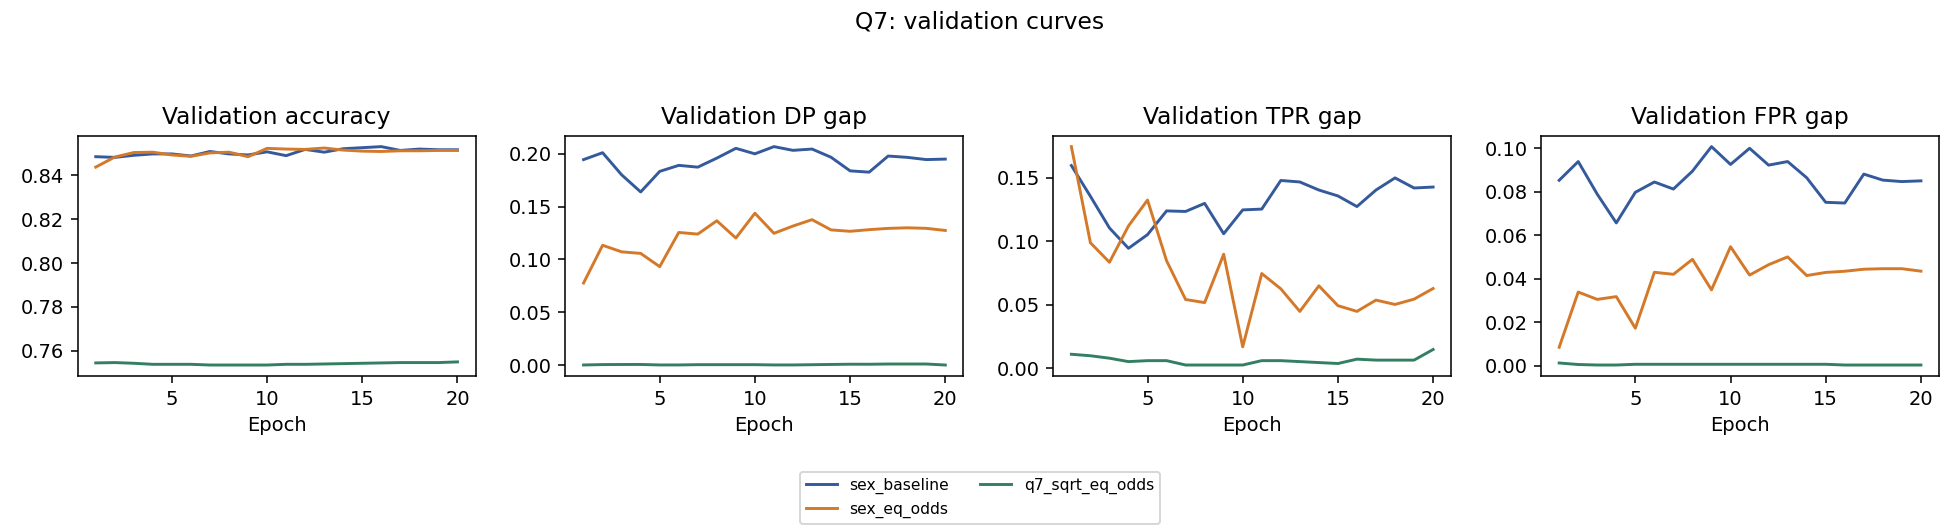

,epoch,alpha,lr_P,val_accuracy,val_TPR_g0,val_TPR_g1
0,1,14.071247,5.050505e-06,0.754541,0.025105,0.014286
1,2,19.899749,2.525253e-06,0.754699,0.020921,0.011278
2,3,24.372115,1.683502e-06,0.754383,0.016736,0.009023
3,4,28.142495,1.262626e-06,0.753909,0.012552,0.007519
4,5,31.464265,1.010101e-06,0.753909,0.012552,0.006767
5,6,34.467376,8.417508e-07,0.753909,0.012552,0.006767
6,7,37.229021,7.215007e-07,0.753593,0.008368,0.006015
7,8,39.799497,6.313131e-07,0.753593,0.008368,0.006015
8,9,42.213742,5.611672e-07,0.753593,0.008368,0.006015
9,10,44.497191,5.050505e-07,0.753593,0.008368,0.006015


In [8]:
run("Q7")
show_fig("q7_comparison.png")
show_fig("q7_curves.png")
display(pd.read_csv(RESULTS/"runs"/"q7_sqrt_eq_odds"/"history.csv")
        [["epoch","alpha","lr_P","val_accuracy","val_TPR_g0","val_TPR_g1"]])


## Q8. Use race as the protected attribute
Three additional fits use White=1 and all other recorded race categories=0.
Race is removed from the inputs; sex is retained. The same train/validation/test
row split is used. Compare all three gaps and note that group sizes differ.


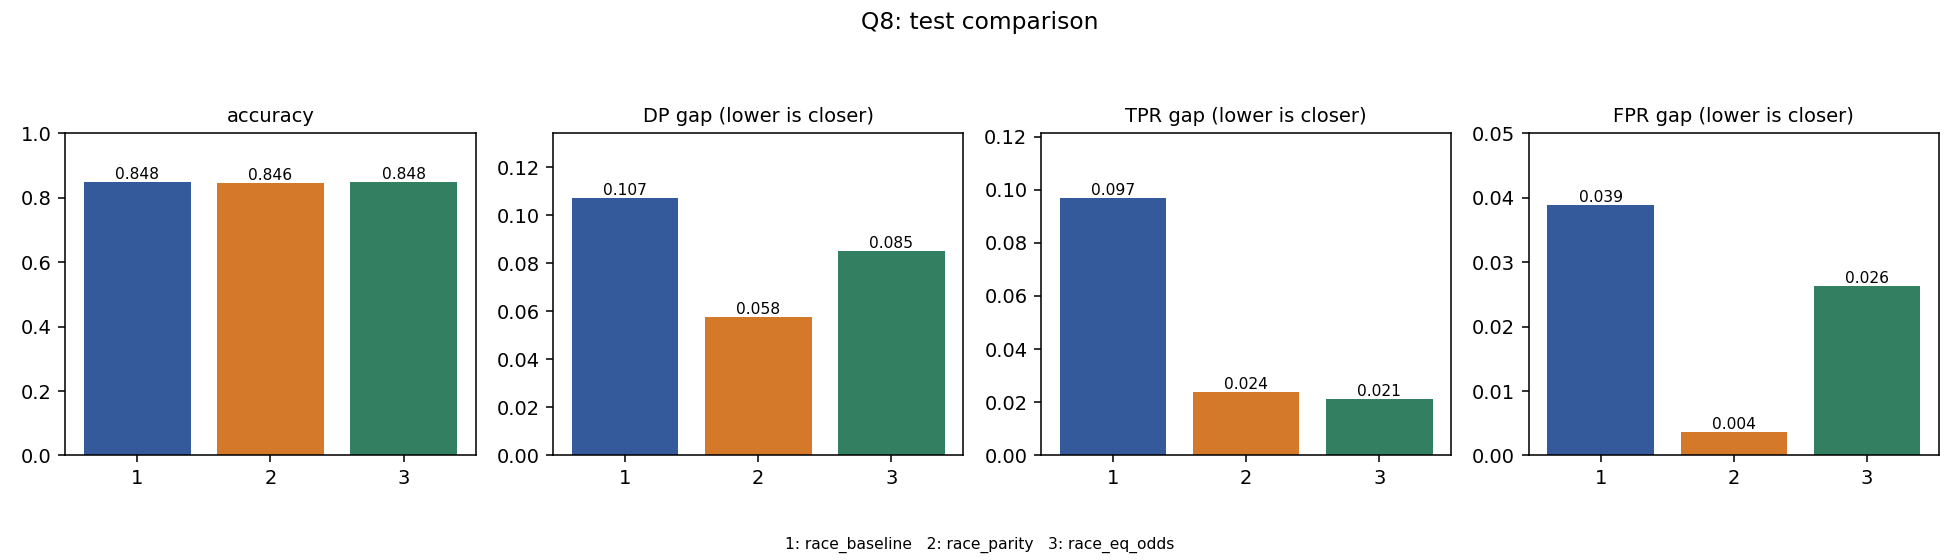

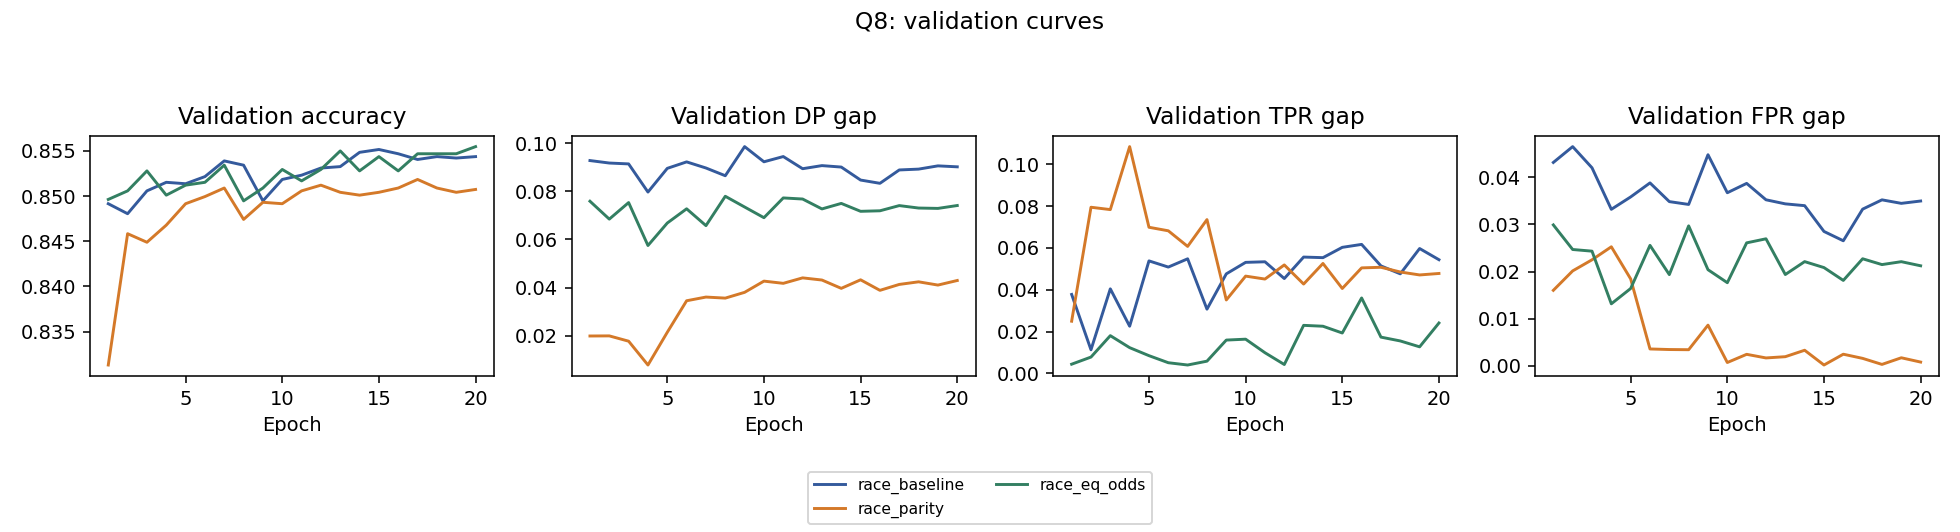

,run,accuracy,DP gap,TPR gap,FPR gap,n_g0,n_g1,base_rate_g0,base_rate_g1
0,sex_baseline,0.847719,0.185978,0.097101,0.082451,4390,9177,0.116173,0.310777
6,race_baseline,0.847940,0.107295,0.096929,0.038945,1887,11680,0.152623,0.263185
7,race_parity,0.846171,0.057741,0.023829,0.003698,1887,11680,0.152623,0.263185
8,race_eq_odds,0.848308,0.085123,0.021190,0.026321,1887,11680,0.152623,0.263185


In [9]:
run("Q8")
show_fig("q8_comparison.png")
show_fig("q8_curves.png")
table=pd.read_csv(RESULTS/"workshop_comparison.csv")
display(table[table.run.isin(["sex_baseline","race_baseline","race_parity","race_eq_odds"])]
        [["run","accuracy","DP gap","TPR gap","FPR gap","n_g0","n_g1","base_rate_g0","base_rate_g1"]])


## Q9. Equal opportunity
One additional fit trains the adversary on Y=1 examples only. The predictor's
classification loss still uses all examples. Compare TPR and FPR gaps with the
equalized-odds model. The FPR gap is not constrained by equal opportunity.


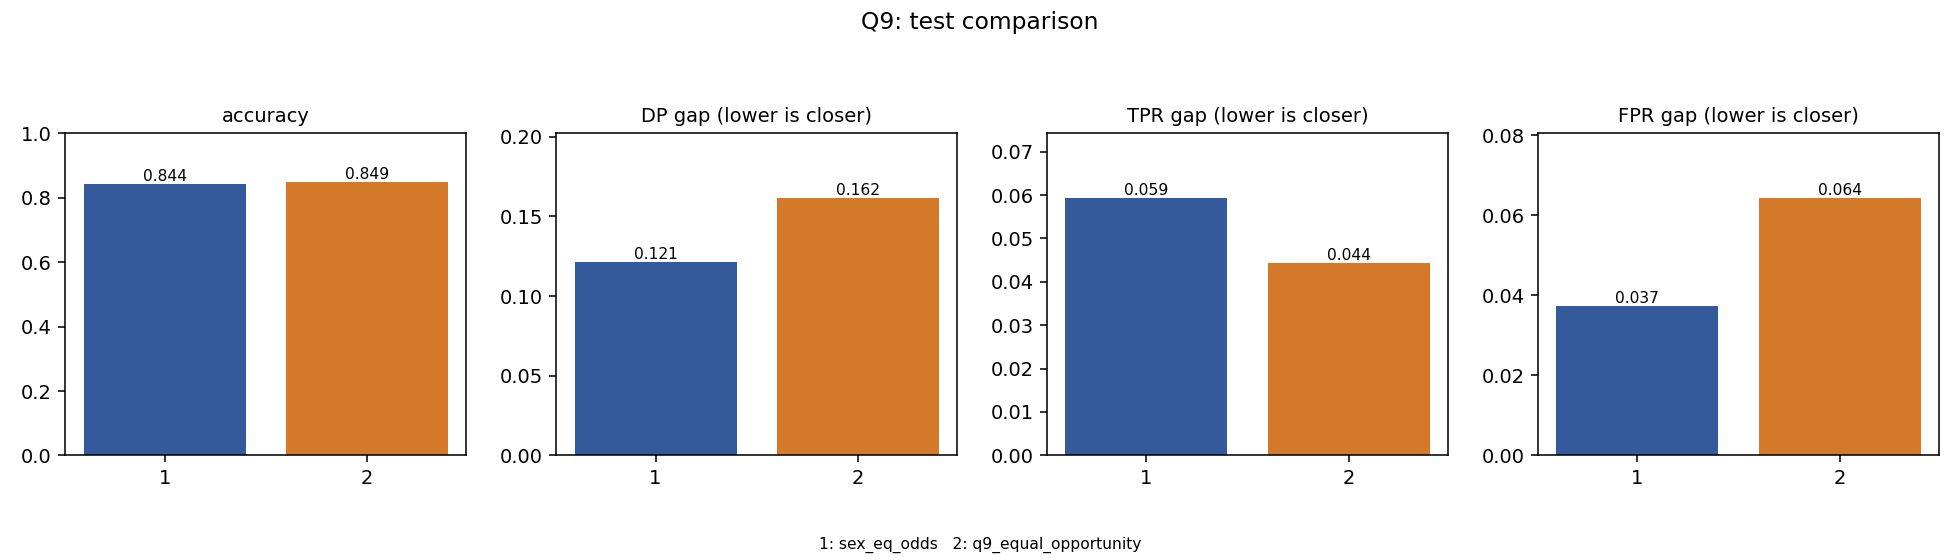

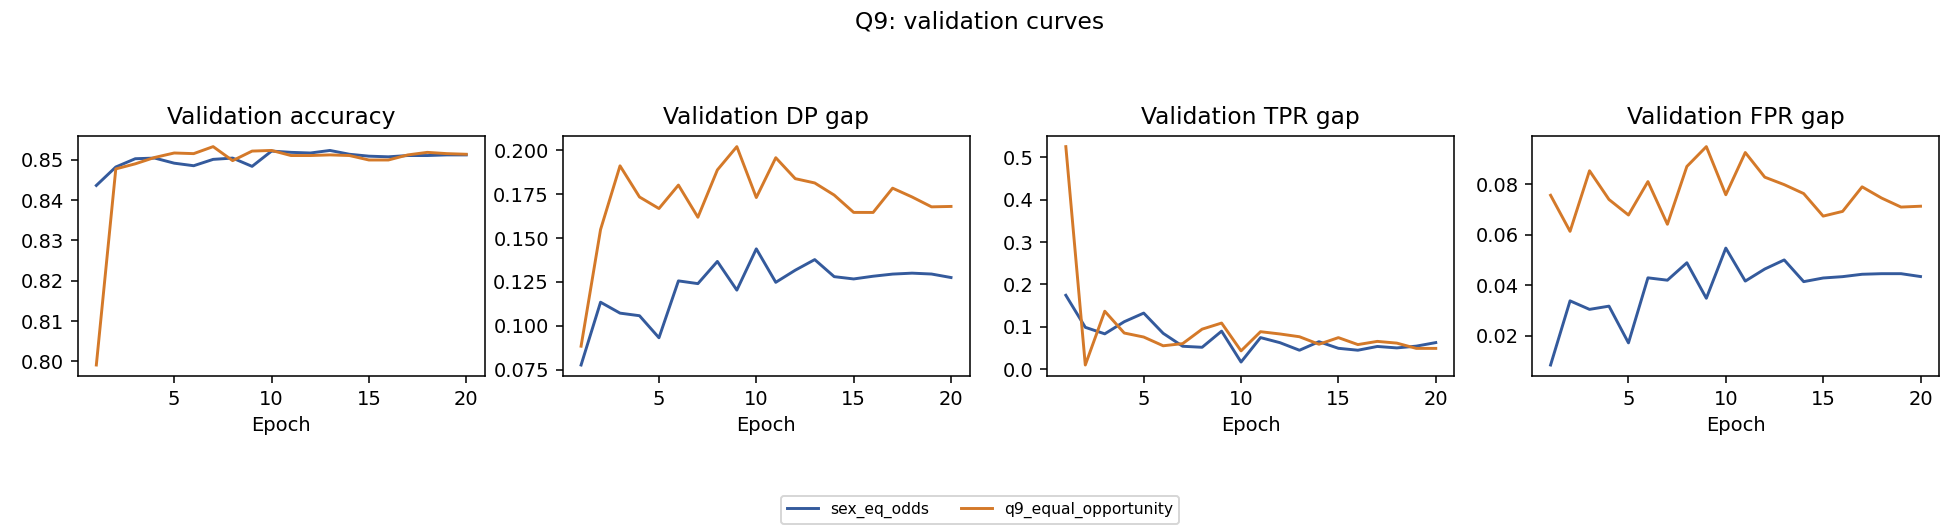

In [10]:
run("Q9")
show_fig("q9_comparison.png")
show_fig("q9_curves.png")


## Q10. Gradient reversal
One additional parity fit uses a torch.autograd.Function reversal layer and one
ordinary (loss_p + loss_a).backward() per batch. The adversary minimizes its loss;
the predictor receives a reversed adversarial gradient without projection.


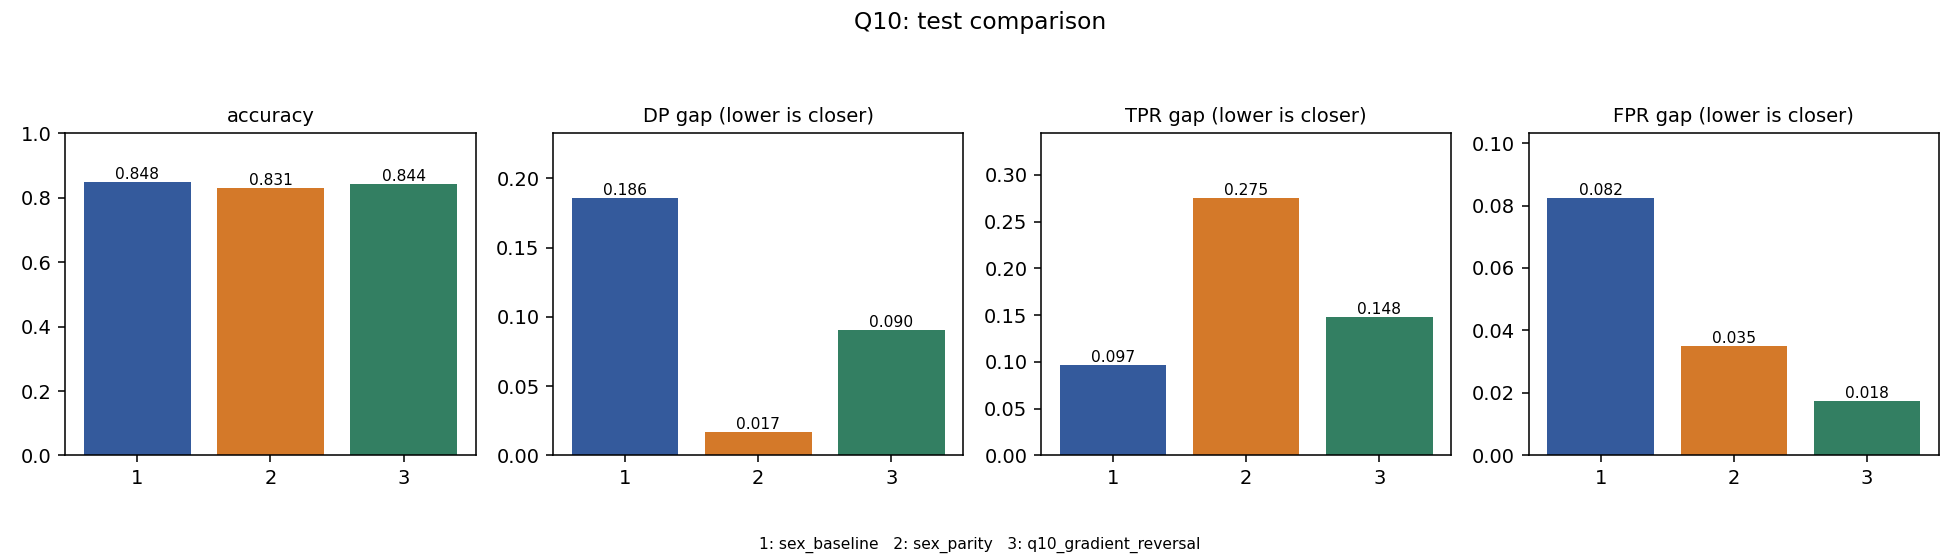

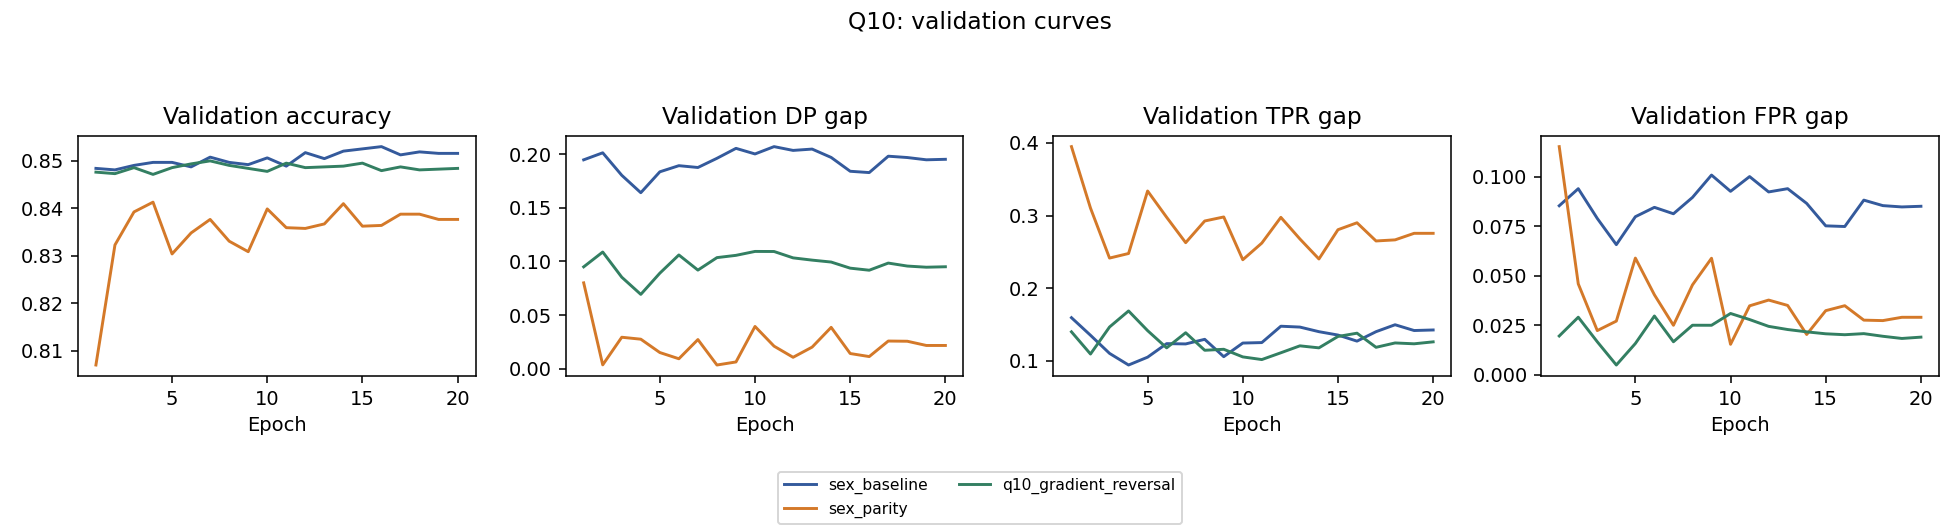

class GradientReversal(torch.autograd.Function):
    """Identity forward; multiply upstream gradient by -alpha backward (Q10)."""
    @staticmethod
    def forward(ctx, x, alpha):
        ctx.alpha = float(alpha)
        return x.view_as(x)

    @staticmethod
    def backward(ctx, grad_output):
        return -ctx.alpha*grad_output, None



In [11]:
run("Q10")
show_fig("q10_comparison.png")
show_fig("q10_curves.png")
from models import GradientReversal
import inspect
print(inspect.getsource(GradientReversal))


## Q11. Adversary on the 64-number hidden representation
One additional parity fit gives the adversary the final hidden activations
instead of the score. Compare DP and the full training trajectory. A linear
adversary may still miss nonlinear group information.


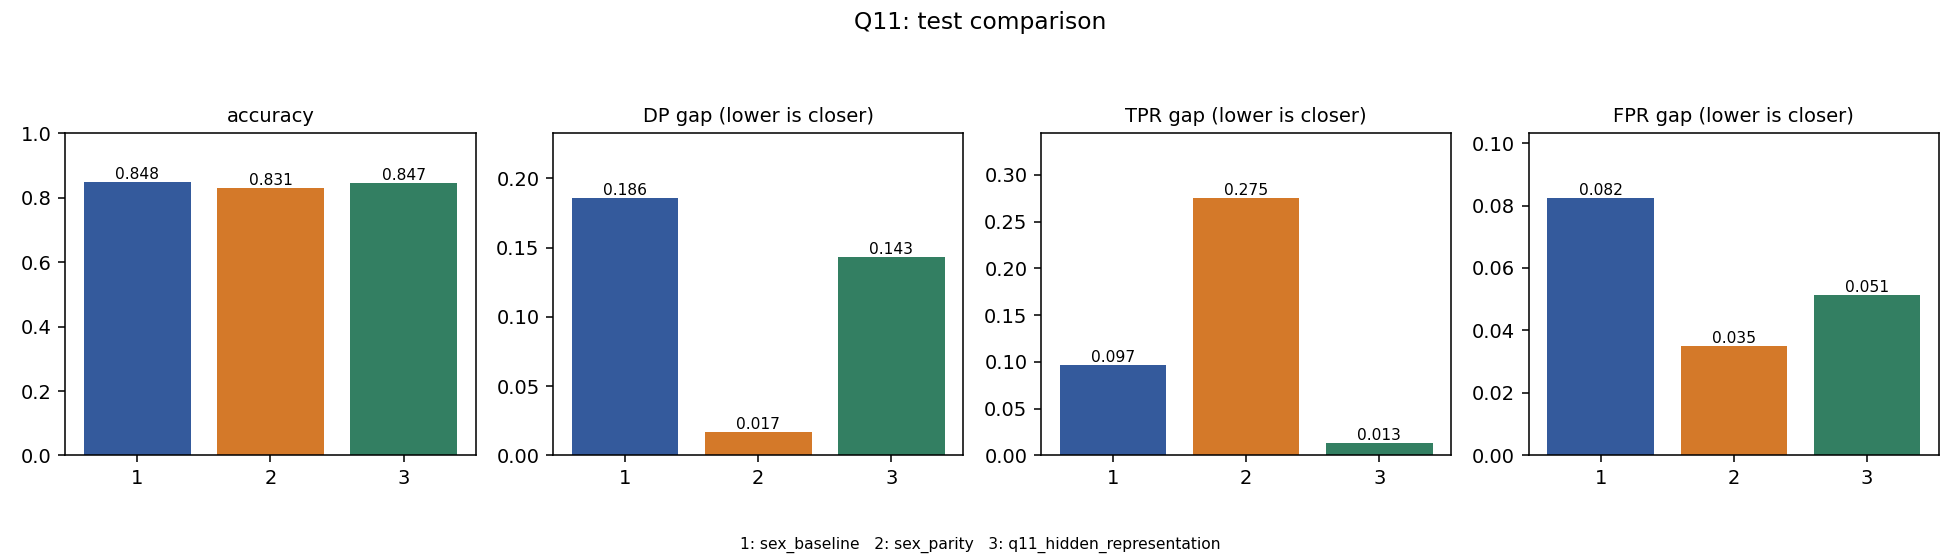

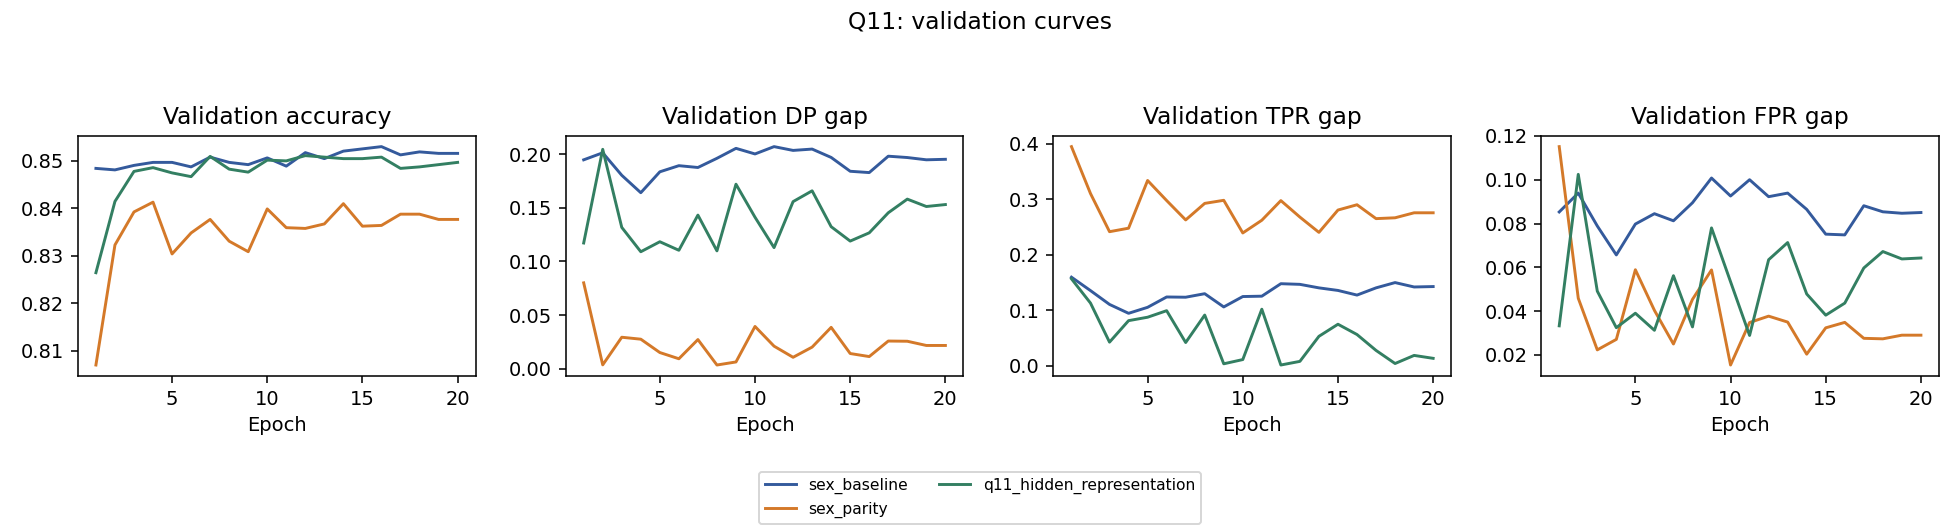

In [12]:
run("Q11")
show_fig("q11_comparison.png")
show_fig("q11_curves.png")


## Q12. Separate group thresholds without retraining
This reuses the baseline and parity models. Validation-only threshold selection
maximizes accuracy subject to DP gap <=0.005. The two thresholds are then frozen
and evaluated on test. This method needs group identity when making decisions.


Thresholds (0=Female, 1=Male): {'0': 0.15611150860786438, '1': 0.6350983381271362}
Validation DP gap: 0.004892299994350674
Test DP gap: 0.007869579862303078


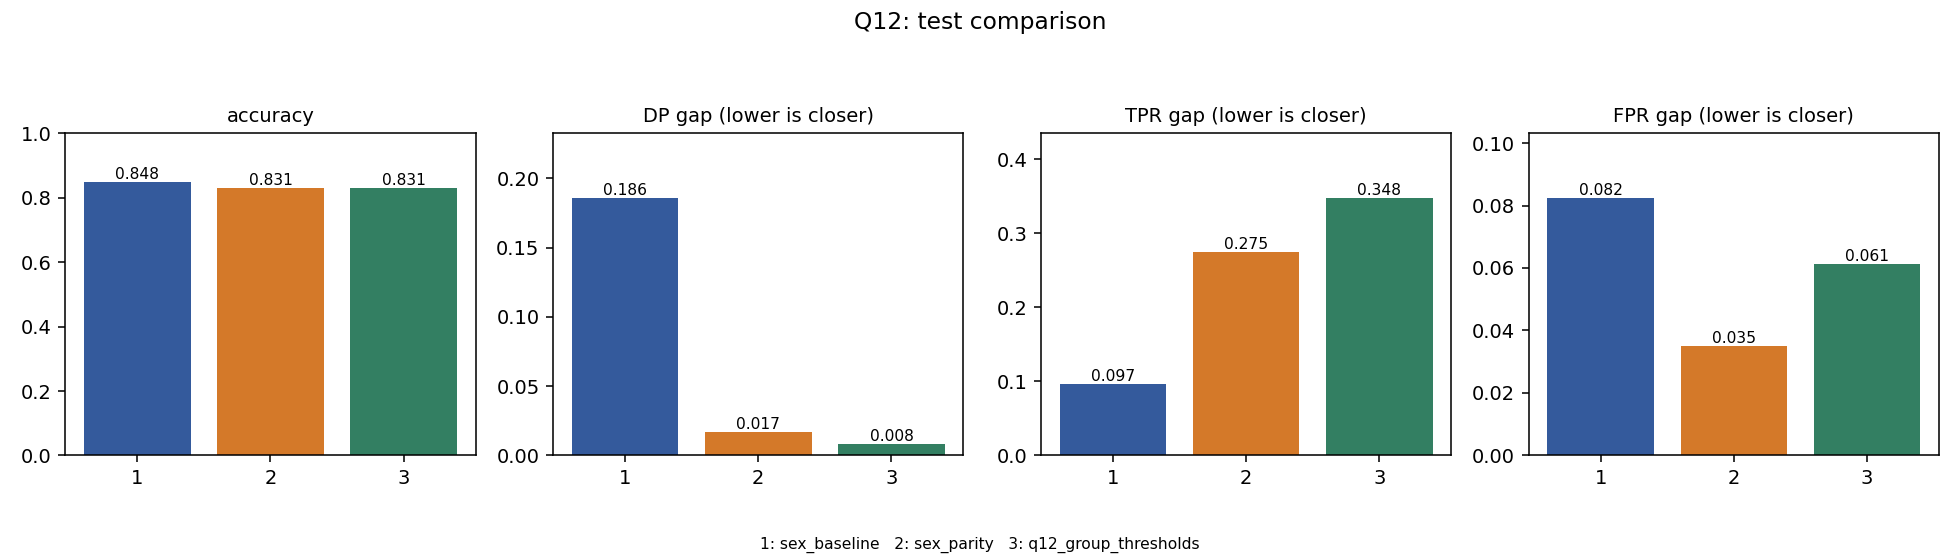

In [13]:
run("Q12")
thresholds=json.loads((RESULTS/"q12_thresholds.json").read_text())
print("Thresholds (0=Female, 1=Male):", thresholds["thresholds"])
print("Validation DP gap:",thresholds["val"]["DP gap"])
print("Test DP gap:",thresholds["test"]["DP gap"])
show_fig("q12_comparison.png")


## Final comparison
There should be 12 trained models plus one threshold-adjusted evaluation.
Gaps are absolute differences between rates, not percentage changes. Multiply
by 100 to express a rate difference in percentage points.


In [14]:
run("all","--summary")
table=pd.read_csv(RESULTS/"workshop_comparison.csv")
display(table[["run","protected","accuracy","DP gap","TPR gap","FPR gap"]])
completed=list((RESULTS/"runs").glob("*/metrics.json"))
print("Completed model fits:",len(completed),"/12")
print("Comparison CSV:",RESULTS/"workshop_comparison.csv")


,run,protected,accuracy,DP gap,TPR gap,FPR gap
0,sex_baseline,sex,0.847719,0.185978,0.097101,0.082451
1,sex_parity,sex,0.831061,0.016698,0.275344,0.034937
2,sex_eq_odds,sex,0.843812,0.121308,0.059350,0.037262
3,q6_parity_hidden32,sex,0.830324,0.019887,0.277241,0.029848
4,q6_eq_odds_hidden32,sex,0.845507,0.129916,0.054363,0.044823
5,q7_sqrt_eq_odds,sex,0.756026,0.000318,0.024139,0.000492
6,race_baseline,race,0.847940,0.107295,0.096929,0.038945
7,race_parity,race,0.846171,0.057741,0.023829,0.003698
8,race_eq_odds,race,0.848308,0.085123,0.021190,0.026321
9,q9_equal_opportunity,sex,0.848603,0.161591,0.044405,0.064315


Completed model fits: 12 /12
Comparison CSV: /content/drive/MyDrive/Week10_Debiasing/Debiasing/results/workshop_comparison.csv


## Export and download
This exports code, checkpoints, full histories, scores, plots, and the comparison
table. The raw dataset is excluded. Download the ZIP before ending the runtime.
Also download the executed notebook if the submission asks for its cell outputs.


In [15]:
ARCHIVE=ROOT/"Week10_Debiasing_Submission.zip"
run("all","--summary","--export",ARCHIVE)
assert ARCHIVE.exists() and ARCHIVE.stat().st_size>0
print("ZIP:",ARCHIVE)
if IN_COLAB:
    from google.colab import files
    files.download(str(ARCHIVE))
else:
    print("Saved locally:",ARCHIVE.resolve())


ZIP: /content/drive/MyDrive/Week10_Debiasing/Week10_Debiasing_Submission.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>